# Notebook 16 — Benchmark thống nhất, nhánh A

Chạy QAOA trên đúng bộ dữ liệu v1 đã khóa, protocol A v1.1: **choice, tight, reference × p=1,2,3 × 5 seed = 45 lượt**. Một lượt kiểm tra vô nghiệm chạy riêng, không cộng vào 45 lượt. Notebook này chỉ thực hiện phần A.

Sampled mean, penalty (3,3), max_abs, COBYLA cap200, 1.024 shots training và 1.024 shots cuối với seed độc lập. Time guard 2400 giây/lượt áp dụng đều cho mọi p theo phụ lục v1.1. Giữ dữ liệu cũ làm thăm dò. File hướng dẫn: `docs/benchmark_a_runbook.md`.

Chạy trong kernel `nt409-khiem`. Một campaign tại một thời điểm. Khi bị dừng, lưu notebook có output và giữ đường dẫn RESUME_DIR; không tự đổi manifest/protocol để chạy tiếp.

## Bước 1 — Kernel và module
Restart Kernel trước khi bắt đầu. Kiểm tra Python thuộc môi trường Conda của bạn.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil,scipy
from IPython.display import display
ROOT=Path.cwd().resolve()
if not (ROOT/"src/qubo.py").is_file():ROOT=ROOT.parent
if not (ROOT/"src/qubo.py").is_file():raise RuntimeError("Mở notebook từ thư mục repo.")
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.benchmark_a_campaign import (load_benchmark,open_campaign,run_preflights,run_campaign,
    verify_campaign,result_rows,export_campaign,prepare_models)
assert tuple(map(int,scipy.__version__.split('.')[:2])) >= (1,16)
print("Python:",sys.executable)
print("RAM available (GiB):",round(psutil.virtual_memory().available/2**30,2))

Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
RAM available (GiB): 13.71


## Bước 2 — Chọn phần chạy và tạo/mở campaign
Lần đầu giữ RESUME_DIR=None. Bạn có thể chạy cả ba instance hoặc chỉ chọn một/hai instance trong RUN_INSTANCE_IDS cho phiên này. Manifest luôn giữ đủ 45 lượt; chọn ít instance không giảm ma trận nghiệm thu.

Resume: dùng đúng đường dẫn in ra, giữ source/runtime/protocol như lúc tạo campaign. RETRY_FAILED chỉ bật sau khi đã xử lý nguyên nhân RAM/time/error. Lượt interrupted được thử lại khi resume; lượt completed luôn được bỏ qua. Tất cả lần thử cũ vẫn được giữ.

In [2]:
RESUME_DIR=None
RUN_INSTANCE_IDS=["p1_choice","p1_tight","p0_reference"]
RETRY_FAILED=False
context=load_benchmark(ROOT)
FOLDER,campaign=open_campaign(ROOT,context,RESUME_DIR)
formal=[t for t in campaign["planned_runs"] if t["role"]=="benchmark"]
assert len(formal)==45 and len(campaign["planned_runs"])==46
print("RESUME_DIR =",repr(FOLDER.relative_to(ROOT).as_posix()))
print("Benchmark:",context["manifest"]["benchmark_id"])
print("Design:",campaign["design_hash"])
print("Phiên này:",RUN_INSTANCE_IDS)
print("Dữ liệu/config đã khóa; 45 lượt chính thức + 1 negative-control smoke.")

RESUME_DIR = 'data/reference_results/phase4h_benchmark_a/benchmark_a_20261010T081035000606Z'
Benchmark: nt409_benchmark_v1_1
Design: 56d4269545a4b94badad9244086e8b35aed0daccc6dfb9e139380ca005c4c8b9
Phiên này: ['p1_choice', 'p1_tight', 'p0_reference']
Dữ liệu/config đã khóa; 45 lượt chính thức + 1 negative-control smoke.


## Bước 3 — Xác minh mô hình và cấu hình
Đây là reference nhỏ để kiểm tra input/QUBO, không phải baseline cổ điển. Các lớp thêm có góc zero ở điểm đầu để giữ cùng trạng thái ban đầu; khi tối ưu các góc đều tự do. Probe bước 4 dùng lớp sâu có góc khác zero.

In [3]:
checks=prepare_models(FOLDER,context)
for check,item in zip(checks,context["manifest"]["instances"]):
    assert check["qubits"]==item["encoded_qubits"]<=23
    assert check["optimal_hosts"]==item["reference_optimal_active_hosts"]
display(pd.DataFrame(checks))
display(pd.DataFrame([dict(p=p,initial_point=point) for p,point in
    context["protocol"]["qaoa"]["initial_points_beta_then_gamma"].items()]))
print("Seed training: 70–74 | seed cuối: 100070–100074 | shots cuối: 1024")

,instance_id,role,qubits,optimal_hosts,qubo_min,model_reference_seconds,cache_hit
0,p1_choice,benchmark,20,1.0,1.0,0.711672,False
1,p1_tight,benchmark,18,2.0,2.0,0.667800,False
2,p0_reference,benchmark,23,2.0,2.0,0.672218,False
3,p1_infeasible,negative_control,20,NaN,5.0,0.667238,False


,p,initial_point
0,1,"[0.3, 1.0]"
1,2,"[0.3, 0.0, 1.0, 0.0]"
2,3,"[0.3, 0.0, 0.0, 1.0, 0.0, 0.0]"


Seed training: 70–74 | seed cuối: 100070–100074 | shots cuối: 1024


## Bước 4 — Đo tài nguyên trước campaign
Mỗi instance/depth chạy ba điểm có đủ lớp hoạt động, phép đo cuối và giải mã. Yêu cầu ít nhất 8 GiB available trước bắt đầu; giữ 4 GiB available và giám sát RSS Python không quá 4 GiB. Đây là kiểm tra tại ranh giới lời gọi, không phải hard cap OS.

Ước lượng thời gian có hệ số 1.5 và dùng evaluation chậm nhất trong probe. Nếu vượt 2400 giây/lượt hoặc không đủ RAM, notebook dừng trước tối ưu. Gửi output và ZIP partial để xem xét; không tự tăng ngân sách. Probe đã passed trong cùng campaign được giữ; từng lượt vẫn kiểm tra RAM hiện tại.

In [4]:
campaign=run_preflights(FOLDER,context,RUN_INSTANCE_IDS,retry_failed=RETRY_FAILED)
probe_rows=[]
for a in campaign["attempts"]:
    if a["kind"]!="probe":continue
    r=json.loads((FOLDER/a["report"]).read_text(encoding="utf-8"))["result"]
    probe_rows.append(dict(instance=a["instance_id"],p=a["reps"],status=a["status"],
        estimated_solver_seconds=r.get("estimated_solver_seconds"),
        peak_rss_mib=r.get("resources",{}).get("process_peak_rss_mib"),reason=r.get("stop_reason")))
display(pd.DataFrame(probe_rows))
passed={(a["instance_id"],a["reps"]) for a in campaign["attempts"] if a["kind"]=="probe" and a["status"]=="passed"}
required={(i,p) for i in RUN_INSTANCE_IDS for p in (1,2,3)}
assert required<=passed,"Probe chưa đạt. Có thể chạy riêng bước 8 để xuất ZIP partial; chưa chạy bước 5."
print("PASS preflight cho các instance đã chọn. Thời gian thực tế có thể khác ước lượng.")

Probe p1_choice p=1
passed 106.24571760013532
Probe p1_choice p=2
passed 109.08534300060455
Probe p1_choice p=3
passed 122.37028980019568
Probe p1_tight p=1
passed 89.65611390094091
Probe p1_tight p=2
passed 82.2421283990916
Probe p1_tight p=3
passed 92.18213970032048
Probe p0_reference p=1
passed 258.67757084966433
Probe p0_reference p=2
passed 591.015761850309
Probe p0_reference p=3
passed 693.3324974995758


,instance,p,status,estimated_solver_seconds,peak_rss_mib,reason
0,p1_choice,1,passed,106.245718,212.277344,Probe estimate includes a 1.5 safety factor; t...
1,p1_choice,2,passed,109.085343,215.652344,Probe estimate includes a 1.5 safety factor; t...
2,p1_choice,3,passed,122.370290,216.898438,Probe estimate includes a 1.5 safety factor; t...
3,p1_tight,1,passed,89.656114,216.898438,Probe estimate includes a 1.5 safety factor; t...
4,p1_tight,2,passed,82.242128,216.898438,Probe estimate includes a 1.5 safety factor; t...
5,p1_tight,3,passed,92.182140,216.898438,Probe estimate includes a 1.5 safety factor; t...
6,p0_reference,1,passed,258.677571,330.210938,Probe estimate includes a 1.5 safety factor; t...
7,p0_reference,2,passed,591.015762,330.949219,Probe estimate includes a 1.5 safety factor; t...
8,p0_reference,3,passed,693.332497,332.410156,Probe estimate includes a 1.5 safety factor; t...


PASS preflight cho các instance đã chọn. Thời gian thực tế có thể khác ước lượng.


## Bước 5 — Chạy phần A và lưu từng lượt
Chạy negative-control smoke một lần, rồi các lượt chính thức đã chọn. Một lượt hoàn tất với 0 nghiệm hoặc optimizer success=False do hết cap vẫn được giữ.

Nếu muốn tạm dừng, Interrupt Kernel một lần và đợi thông báo lưu; không đóng ứng dụng ngay lúc ghi file. Nếu kernel bị tắt đột ngột, resume ghi nhận lượt đang chạy là interrupted hoặc khôi phục report cuối đã ghi, rồi tiếp tục. Không mở hai kernel cùng campaign.

In [5]:
campaign=run_campaign(FOLDER,context,RUN_INSTANCE_IDS,retry_failed=RETRY_FAILED,progress=True)
rows=result_rows(FOLDER,campaign)
done=sum(r["role"]=="benchmark" and r["status"]=="completed" for r in rows)
print(f"Hoàn tất chính thức: {done}/45")
display(pd.DataFrame(rows)[["instance_id","p","seed","role","status","attempt_count","nfev","stop_reason"]])

Run p1_infeasible p=1 seed=70 (negative_control)
  eval 1: E=642.953125, 0.1s
completed {'status': 3, 'success': False, 'message': 'Return from COBYLA because the objective function has been evaluated MAXFUN times.', 'nfev': 8}
Run p1_choice p=1 seed=70 (benchmark)
  eval 1: E=349.503906, 0.1s
  eval 10: E=70.484375, 0.7s
  eval 20: E=68.313477, 1.4s
  eval 30: E=69.254883, 2.1s
completed {'status': 0, 'success': True, 'message': 'Return from COBYLA because the trust region radius reaches its lower bound.', 'nfev': 33}
Run p1_choice p=1 seed=71 (benchmark)
  eval 1: E=343.416992, 0.1s
  eval 10: E=94.143555, 0.7s
  eval 20: E=83.797852, 1.4s
  eval 30: E=82.204102, 2.0s
completed {'status': 0, 'success': True, 'message': 'Return from COBYLA because the trust region radius reaches its lower bound.', 'nfev': 32}
Run p1_choice p=1 seed=72 (benchmark)
  eval 1: E=333.290039, 0.1s
  eval 10: E=91.382813, 0.7s
  eval 20: E=83.725586, 1.3s
  eval 30: E=84.458984, 2.0s
completed {'status': 0, 

,instance_id,p,seed,role,status,attempt_count,nfev,stop_reason
0,p1_choice,1,70,benchmark,completed,1,33,Return from COBYLA because the trust region ra...
1,p1_choice,1,71,benchmark,completed,1,32,Return from COBYLA because the trust region ra...
2,p1_choice,1,72,benchmark,completed,1,37,Return from COBYLA because the trust region ra...
3,p1_choice,1,73,benchmark,completed,1,39,Return from COBYLA because the trust region ra...
4,p1_choice,1,74,benchmark,completed,1,34,Return from COBYLA because the trust region ra...
5,p1_choice,2,70,benchmark,completed,1,41,Return from COBYLA because the trust region ra...
6,p1_choice,2,71,benchmark,completed,1,37,Return from COBYLA because the trust region ra...
7,p1_choice,2,72,benchmark,completed,1,38,Return from COBYLA because the trust region ra...
8,p1_choice,2,73,benchmark,completed,1,37,Return from COBYLA because the trust region ra...
9,p1_choice,2,74,benchmark,completed,1,37,Return from COBYLA because the trust region ra...


## Bước 6 — Kiểm tra report và xem kết quả từng lượt
Xác minh lại hash, model, seed, counts, decoded bits, energy, stop reason và quy tắc chọn output. Quy tắc của benchmark là objective → frequency → thứ tự bits; không dùng slack energy để phá hòa.

P_opt là tần suất trong batch cuối, không phải xác suất lý tưởng exact. Không chọn seed tốt nhất rồi gọi đó là kết quả chung.

In [6]:
campaign=json.loads((FOLDER/"campaign.json").read_text(encoding="utf-8"))
verified=verify_campaign(FOLDER,campaign,context)
rows=result_rows(FOLDER,campaign)
table=pd.DataFrame(rows)
formal_table=table[table["role"]=="benchmark"].copy()
for column in ("feasible_probability","optimal_probability","ground_probability"):
    formal_table[column+"_percent"]=100*pd.to_numeric(formal_table[column],errors="coerce")
display(formal_table[["instance_id","p","seed","status","found_valid","selected_objective","optimality_gap",
    "feasible_probability_percent","optimal_probability_percent","mode_tie_count","optimizer_success","total_seconds"]])
display(table[table["role"]=="negative_control"][["instance_id","status","found_valid","found_optimal","stop_reason"]])

,instance_id,p,seed,status,found_valid,selected_objective,optimality_gap,feasible_probability_percent,optimal_probability_percent,mode_tie_count,optimizer_success,total_seconds
0,p1_choice,1,70,completed,True,1.0,0.0,2.148438,0.292969,1,True,4.414061
1,p1_choice,1,71,completed,True,1.0,0.0,2.050781,0.488281,1,True,4.276175
2,p1_choice,1,72,completed,True,2.0,1.0,1.953125,0.000000,2,True,4.604039
3,p1_choice,1,73,completed,True,2.0,1.0,2.246094,0.000000,9,True,4.863302
4,p1_choice,1,74,completed,True,1.0,0.0,2.636719,0.488281,6,True,4.468238
5,p1_choice,2,70,completed,True,1.0,0.0,2.246094,0.195312,5,True,10.266538
6,p1_choice,2,71,completed,True,1.0,0.0,1.562500,0.097656,1,True,9.726050
7,p1_choice,2,72,completed,True,2.0,1.0,2.636719,0.000000,6,True,10.678107
8,p1_choice,2,73,completed,True,1.0,0.0,1.660156,0.097656,5,True,10.078997
9,p1_choice,2,74,completed,True,1.0,0.0,2.050781,0.097656,1,True,10.238855


,instance_id,status,found_valid,found_optimal,stop_reason
45,p1_infeasible,completed,False,None,Return from COBYLA because the objective funct...


## Bước 7 — Tổng hợp theo instance và p
Bảng luôn ghi số planned/completed/pending/failed. Mean P_opt chỉ lấy các lượt completed và phải đọc cùng số lượng; nhóm chưa đủ 5 lượt không phải kết quả cuối. Đồ thị vẽ từng seed đã hoàn tất, không phải khoảng tin cậy.

RSS peak trong report là đỉnh vòng đời tiến trình, có thể gồm hoạt động trước đó. Thời gian total của runner chưa bao gồm mọi chi phí tạo model/reference và preflight; bước 3 ghi model/reference riêng (có nhãn cache_hit), probe có report timing riêng. Thời gian audit/ghi file và thời gian nghỉ giữa các phiên không nằm trong total_seconds; không gọi đây là wall-time end-to-end.

,instance,p,planned,completed,pending,stopped_or_error,valid_runs,optimal_runs,mean_measured_Popt_percent,mean_runner_seconds
0,p1_choice,1,5,5,0,0,5,3,0.253906,4.525163
1,p1_choice,2,5,5,0,0,5,4,0.097656,10.197709
2,p1_choice,3,5,5,0,0,5,3,0.097656,17.250295
3,p1_tight,1,5,5,0,0,4,4,0.273438,4.736877
4,p1_tight,2,5,5,0,0,5,5,0.410156,5.073841
5,p1_tight,3,5,5,0,0,0,0,0.000000,5.973491
6,p0_reference,1,5,5,0,0,2,2,0.058594,22.649723
7,p0_reference,2,5,5,0,0,3,3,0.078125,59.726040
8,p0_reference,3,5,5,0,0,0,0,0.000000,91.573627


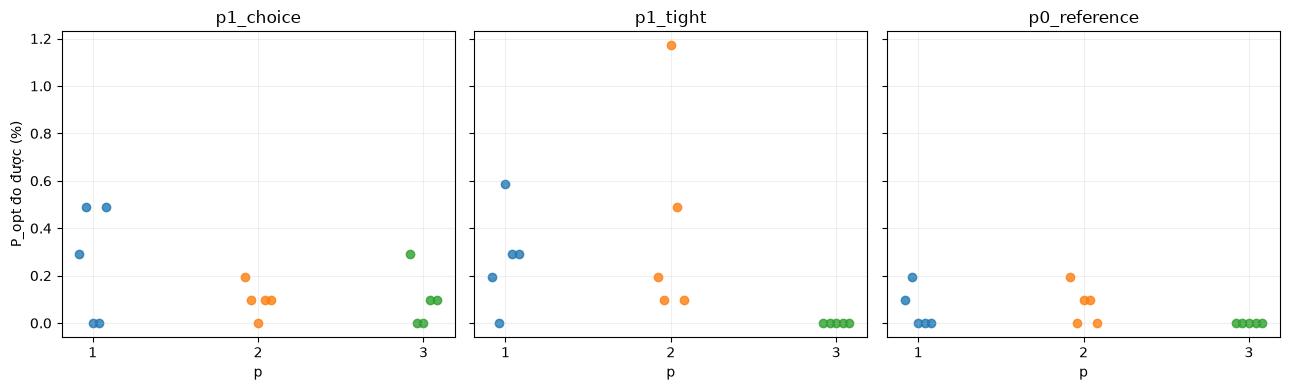

In [7]:
summary=[]
for (instance_id,p),group in formal_table.groupby(["instance_id","p"],sort=False):
    completed=group[group["status"]=="completed"]
    summary.append(dict(instance=instance_id,p=p,planned=len(group),completed=len(completed),
        pending=int((group["status"]=="pending").sum()),
        stopped_or_error=int((~group["status"].isin(["pending","completed"])).sum()),
        valid_runs=int((completed["found_valid"]==True).sum()),optimal_runs=int((completed["found_optimal"]==True).sum()),
        mean_measured_Popt_percent=completed["optimal_probability_percent"].mean(),
        mean_runner_seconds=pd.to_numeric(completed["total_seconds"],errors="coerce").mean()))
display(pd.DataFrame(summary))
fig,axes=plt.subplots(1,3,figsize=(13,4),sharey=True)
for ax,instance_id in zip(axes,["p1_choice","p1_tight","p0_reference"]):
    group=formal_table[(formal_table["instance_id"]==instance_id)&(formal_table["status"]=="completed")]
    for p in (1,2,3):
        points=group[group["p"]==p].sort_values("seed")
        ax.scatter(np.full(len(points),p)+np.linspace(-.08,.08,len(points)),points["optimal_probability_percent"],alpha=.8)
    ax.set(title=instance_id,xlabel="p",xticks=[1,2,3]);ax.grid(alpha=.2)
axes[0].set_ylabel("P_opt đo được (%)")
fig.tight_layout();fig.savefig(FOLDER/"branch_a_quality.png",dpi=150);plt.show()

## Bước 8 — Xuất kết quả đầy đủ hoặc partial
Bước này có thể chạy riêng sau khi đã tạo campaign ở bước 2, kể cả khi probe bị chặn. ZIP giữ toàn bộ attempts, kể cả failure/interruption và probe, cùng snapshot thiết kế trong campaign.json.

Sau khi chạy đủ: Save As notebook có output thành `16_qaoa_unified_benchmark_a_executed.ipynb`. Gửi notebook và ZIP được in bên dưới. Nếu chưa đủ 45 lượt, dùng RESUME_DIR để tiếp tục; không tạo campaign mới chỉ vì kết quả chưa tốt.

In [8]:
EXPORT_PATH,rows=export_campaign(FOLDER,context)
formal=[r for r in rows if r["role"]=="benchmark"]
negative=[r for r in rows if r["role"]=="negative_control"]
complete=sum(r["status"]=="completed" for r in formal)
if complete==45 and len(negative)==1 and negative[0]["status"]=="completed" and negative[0]["found_valid"]==False:
    print("PASS — branch A: 45/45 formal runs, negative control and source reports verified.")
else:
    print(f"PARTIAL — {complete}/45 formal runs completed. ZIP giữ đầy đủ trạng thái; chưa nghiệm thu xong.")
print("Gửi ZIP:",EXPORT_PATH.relative_to(ROOT).as_posix())
print("RESUME_DIR =",repr(FOLDER.relative_to(ROOT).as_posix()))
print("Save As: 16_qaoa_unified_benchmark_a_executed.ipynb")

PASS — branch A: 45/45 formal runs, negative control and source reports verified.
Gửi ZIP: data/reference_results/phase4h_benchmark_a/benchmark_a_20261010T081035000606Z/benchmark_a_20261010T081035000606Z.zip
RESUME_DIR = 'data/reference_results/phase4h_benchmark_a/benchmark_a_20261010T081035000606Z'
Save As: 16_qaoa_unified_benchmark_a_executed.ipynb
